<a href="https://colab.research.google.com/github/saurabhsen848/Deep-Learning/blob/main/Project10_Overfitting_Underfitting_Iris.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 10: Overfitting and Underfitting Analysis
**Dataset:** Iris | **Models:** Neural networks (scikit-learn `MLPClassifier`)

**Goal:** Compare networks of different complexity trained on the same data, and identify underfitting, appropriate fitting and overfitting by comparing training and testing performance.

## Setup and imports

In [11]:
import numpy as np, warnings
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import log_loss
warnings.filterwarnings("ignore")
SEED = 42

## Task 1 (part 1): Load data and prepare one shared train/test split
Iris is very easy, so to make the effect visible I use a **small training set (30%)** and flip **10% of the training labels** at random. The test labels stay clean. Every model uses exactly the same split.

In [12]:
X, y = load_iris(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.7, stratify=y, random_state=SEED)

rng = np.random.RandomState(SEED)
noisy = rng.choice(len(y_tr), size=int(0.10*len(y_tr)), replace=False)
y_tr_noisy = y_tr.copy()
y_tr_noisy[noisy] = rng.randint(0, 3, size=len(noisy))

sc = StandardScaler().fit(X_tr)
X_tr, X_te = sc.transform(X_tr), sc.transform(X_te)
print("Train samples:", len(y_tr), "| Test samples:", len(y_te))

Train samples: 45 | Test samples: 105


## Task 1 (part 2): Define three architectures
| Model | Hidden layers | Epochs | Expected behaviour |
|---|---|---|---|
| A | 1 neuron | 5 | Underfit |
| B | 8 neurons, L2 = 0.01 | 200 | Good fit |
| C | 128 x 128 x 128 | 2000 | Overfit |

In [13]:
# name: (hidden layers, epochs, learning rate, L2 alpha)
models = {
    "A: Too simple (1 neuron, 5 epochs)":     ((1,),          5,    0.001, 0.0),
    "B: Balanced (8 neurons, 200 epochs)":    ((8,),          200,  0.01,  0.01),
    "C: Too complex (128x128x128, 2000 ep.)": ((128,128,128), 2000, 0.01,  0.0),
}

## Task 2: Train and evaluate on the same data
Training is done epoch by epoch with `partial_fit` so we can record accuracy and log loss on both the training and test sets over time.

In [14]:
def run(hidden, epochs, lr, alpha):
    m = MLPClassifier(hidden_layer_sizes=hidden, learning_rate_init=lr,
                      alpha=alpha, solver="adam", random_state=SEED)
    h = {"tr": [], "te": [], "trl": [], "tel": []}
    step = max(1, epochs // 100)
    for ep in range(epochs):
        m.partial_fit(X_tr, y_tr_noisy, classes=[0, 1, 2])
        if ep % step == 0 or ep == epochs - 1:
            h["tr"].append(m.score(X_tr, y_tr_noisy))
            h["te"].append(m.score(X_te, y_te))
            h["trl"].append(log_loss(y_tr_noisy, m.predict_proba(X_tr), labels=[0,1,2]))
            h["tel"].append(log_loss(y_te, m.predict_proba(X_te), labels=[0,1,2]))
    return m, h

trained = {}
print(f"{'Model':42s}{'Params':>8s}{'TrainAcc':>10s}{'TestAcc':>9s}{'Gap':>7s}{'TrainLoss':>11s}{'TestLoss':>10s}")
for name, (hid, ep, lr, a) in models.items():
    m, h = run(hid, ep, lr, a)
    trained[name] = (m, h, ep)
    params = sum(w.size for w in m.coefs_) + sum(b.size for b in m.intercepts_)
    print(f"{name:42s}{params:8d}{h['tr'][-1]:10.3f}{h['te'][-1]:9.3f}"
          f"{h['tr'][-1]-h['te'][-1]:7.3f}{h['trl'][-1]:11.3f}{h['tel'][-1]:10.3f}")

Model                                       Params  TrainAcc  TestAcc    Gap  TrainLoss  TestLoss
A: Too simple (1 neuron, 5 epochs)              11     0.356    0.343  0.013      1.205     1.261
B: Balanced (8 neurons, 200 epochs)             67     0.933    0.952 -0.019      0.172     0.143
C: Too complex (128x128x128, 2000 ep.)       34051     1.000    0.905  0.095      0.000     0.894


### Learning curves (accuracy on top, log loss on bottom)

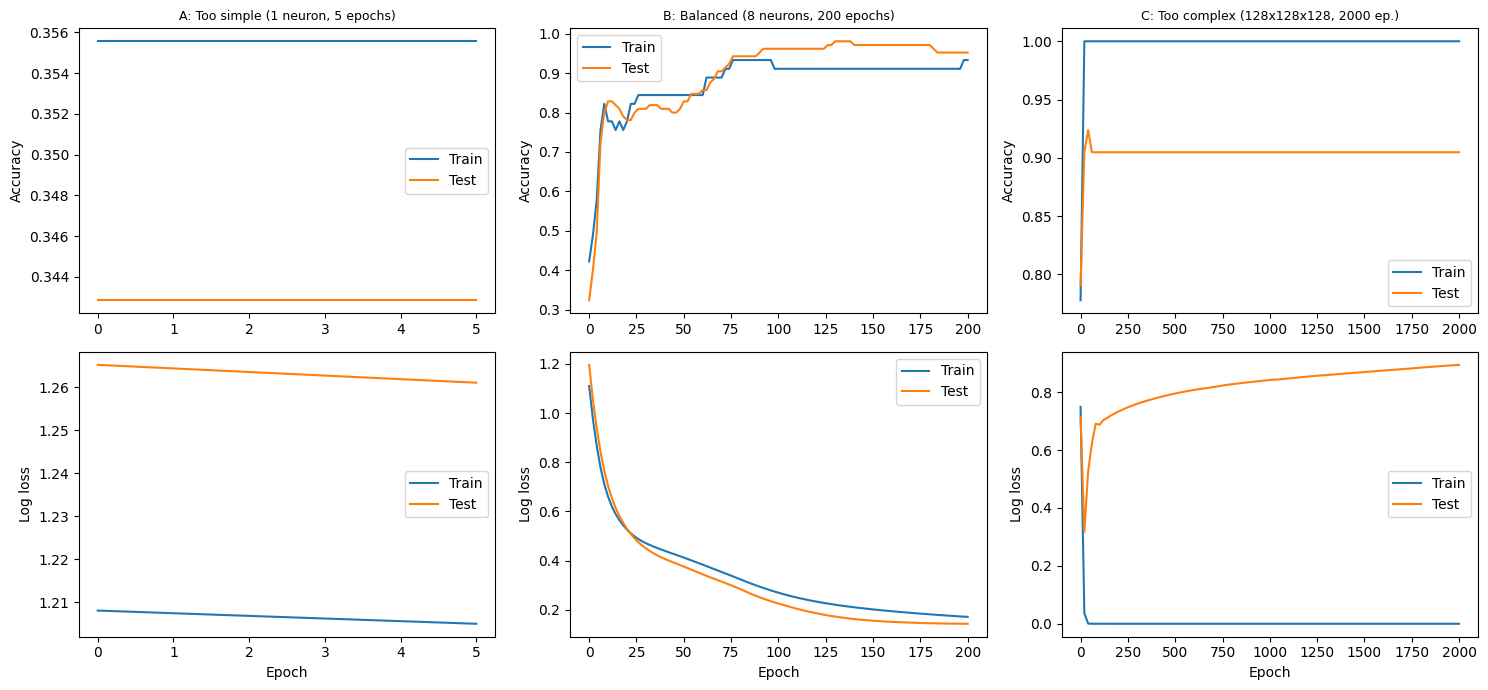

In [15]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for i, (name, (m, h, ep)) in enumerate(trained.items()):
    x = np.linspace(0, ep, len(h["tr"]))
    ax[0,i].plot(x, h["tr"], label="Train"); ax[0,i].plot(x, h["te"], label="Test")
    ax[0,i].set_title(name, fontsize=9); ax[0,i].set_ylabel("Accuracy"); ax[0,i].legend()
    ax[1,i].plot(x, h["trl"], label="Train"); ax[1,i].plot(x, h["tel"], label="Test")
    ax[1,i].set_xlabel("Epoch"); ax[1,i].set_ylabel("Log loss"); ax[1,i].legend()
plt.tight_layout(); plt.show()

### Complexity sweep: train vs test accuracy as the network grows

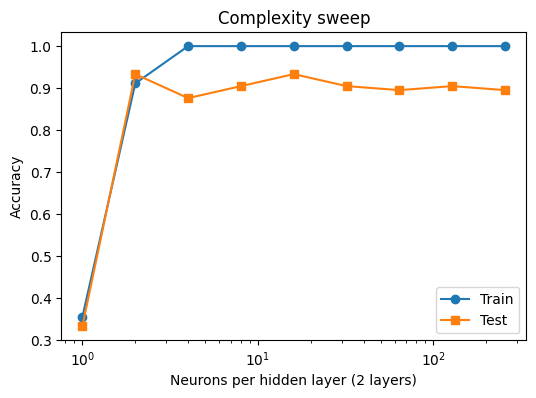

   1 neurons: train=0.356 test=0.333
   2 neurons: train=0.911 test=0.933
   4 neurons: train=1.000 test=0.876
   8 neurons: train=1.000 test=0.905
  16 neurons: train=1.000 test=0.933
  32 neurons: train=1.000 test=0.905
  64 neurons: train=1.000 test=0.895
 128 neurons: train=1.000 test=0.905
 256 neurons: train=1.000 test=0.895


In [16]:
sizes = [1, 2, 4, 8, 16, 32, 64, 128, 256]
trs, tes = [], []
for s in sizes:
    m = MLPClassifier(hidden_layer_sizes=(s, s), max_iter=3000, random_state=SEED).fit(X_tr, y_tr_noisy)
    trs.append(m.score(X_tr, y_tr_noisy)); tes.append(m.score(X_te, y_te))

plt.figure(figsize=(6, 4))
plt.semilogx(sizes, trs, "o-", label="Train"); plt.semilogx(sizes, tes, "s-", label="Test")
plt.xlabel("Neurons per hidden layer (2 layers)"); plt.ylabel("Accuracy")
plt.title("Complexity sweep"); plt.legend(); plt.show()
for s, a, b in zip(sizes, trs, tes): print(f"{s:4d} neurons: train={a:.3f} test={b:.3f}")